# MESA to GYRE oscillation walkthrough

This notebook exercises the reusable pipeline without copying its implementation. It validates a MESA GYRE-format pulse model, constructs the namelist, optionally runs GYRE, and inspects the mode summary and eigenfunctions.

## Expected artifacts

The input model may live anywhere. The run directory under `results/run_gyre/` receives `gyre.in`, a copied model, metadata, the solver log, `summary.h5`, `modes.csv`, and one `detail.l*.n*.h5` file per saved mode. Run this notebook from the repository root.

In [10]:
from pathlib import Path

import os

os.environ["GYRE_DIR"] = "/Users/mchau/gyre-9.1.1"

# Edit these parameters. MODEL_PATH must be a MESA pulse file written
# with pulse_data_format = 'GYRE', not an ordinary profile*.data file.
MODEL_PATH = Path(
    '/Users/mchau/mesa_tutorial/results/mams_profiles/'
    'TAMS3Msun_Z0p0142/'
    'TAMS3Msun_Z0p0142.mesa'
)
PROJECT_ROOT = Path('/Users/mchau/mesa_tutorial/mesa-gyre-oscillations')

OUTPUT_DIR = (
    PROJECT_ROOT
    / 'results'
    / 'run_gyre'
    / MODEL_PATH.stem
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GYRE_EXECUTABLE = Path('/Users/mchau/gyre-9.1.1/bin/gyre')  # Example: Path('/path/to/gyre/bin/gyre')
RUN_GYRE = True        # Change to True when the configuration is ready.

HARMONIC_DEGREES = (2,)

N_PG_MIN, N_PG_MAX = -20, 20

FREQ_MIN = 0.1
FREQ_MAX = 30
N_FREQ = 10000

SCAN_FREQ_UNITS = 'NONE'
OUTPUT_FREQ_UNITS = 'CYC_PER_DAY'

GRID_TYPE = 'INVERSE'
THREADS = 1

In [11]:
import csv
import sys
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root(start):
    for candidate in (start, *start.parents):
        module = candidate / 'scripts' / 'run_gyre' / 'pipeline' / 'gyre_pipeline.py'
        if module.is_file():
            return candidate
    raise FileNotFoundError('Run this notebook from inside the cloned repository.')

repo_root = find_repo_root(Path.cwd().resolve())
pipeline_dir = repo_root / 'scripts' / 'run_gyre' / 'pipeline'
if str(pipeline_dir) not in sys.path:
    sys.path.insert(0, str(pipeline_dir))
if not MODEL_PATH.is_absolute():
    MODEL_PATH = repo_root / MODEL_PATH
if not OUTPUT_DIR.is_absolute():
    OUTPUT_DIR = repo_root / OUTPUT_DIR

from gyre_pipeline import (
    RunConfig, load_gyre_hdf5, load_summary, render_gyre_input,
    run_pipeline, validate_model_file,
)

plt.rcParams.update({
    'font.size': 16,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 15,
    'axes.titlesize': 0,
    'lines.linewidth': 2.2,
    'lines.markersize': 6,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
})

## 1. Validate the stellar model

This inexpensive check catches missing files and ordinary MESA profile tables before GYRE is launched.

In [12]:
MODEL_AVAILABLE = MODEL_PATH.is_file()
if MODEL_AVAILABLE:
    model_info = validate_model_file(MODEL_PATH)
    model_info
else:
    print(
        f'Model not found: {MODEL_PATH}\n'
        'Copy a MESA GYRE-format pulse file there or edit MODEL_PATH, '
        'then rerun this cell.'
    )

## 2. Build and inspect the GYRE configuration

The scan bounds and output units are independent. Here the scan uses dimensionless angular frequency while the output frequency column uses cycles per day.

In [13]:
config = RunConfig(
    harmonic_degrees=HARMONIC_DEGREES,
    n_pg_min=N_PG_MIN,
    n_pg_max=N_PG_MAX,
    freq_min=FREQ_MIN,
    freq_max=FREQ_MAX,
    n_freq=N_FREQ,
    freq_units=SCAN_FREQ_UNITS,
    output_freq_units=OUTPUT_FREQ_UNITS,
    grid_type=GRID_TYPE,
    threads=THREADS,
)
print(render_gyre_input(config))

&constants
/

&model
  model_type = 'EVOL'
  file = 'input_model.mesa'
  file_format = 'MESA'
/

&mode
  l = 2
  n_pg_min = -20
  n_pg_max = 20
/

&osc
  outer_bound = 'VACUUM'
/

&rot
/

&num
  diff_scheme = 'COLLOC_GL4'
/

&scan
  grid_type = 'INVERSE'
  freq_min = 0.1
  freq_max = 30
  n_freq = 10000
  freq_units = 'NONE'
/

&grid
  w_osc = 10
  w_exp = 2
  w_ctr = 10
/

&ad_output
  summary_file = 'summary.h5'
  summary_item_list = 'l,n_pg,n_p,n_g,omega,freq,E_norm,R_star,M_star'
  detail_template = 'detail.l%l.n%n.h5'
  detail_item_list = 'l,n_pg,omega,x,xi_r,xi_h,c_1,As,V_2,Gamma_1,rho,M_r'
  freq_units = 'CYC_PER_DAY'
/

&nad_output
/



## 3. Prepare a dry run

The first execution creates the portable model copy, `gyre.in`, and metadata without requiring a GYRE installation. An existing run directory is preserved.

In [14]:
if MODEL_AVAILABLE and not OUTPUT_DIR.exists():
    preview = run_pipeline(
        MODEL_PATH, OUTPUT_DIR, config, dry_run=True, overwrite=False
    )
    print(f'Prepared {preview.output_dir}')
elif OUTPUT_DIR.exists():
    print(f'Preserving existing run directory: {OUTPUT_DIR}')
else:
    print('Dry run skipped until MODEL_PATH is available.')

Preserving existing run directory: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/TAMS3Msun_Z0p0142


## 4. Optional end-to-end calculation

Set `RUN_GYRE = True` in the parameter cell after reviewing the namelist. This replaces the dry-run directory with the complete calculation.

In [15]:
if RUN_GYRE and MODEL_AVAILABLE:
    result = run_pipeline(
        MODEL_PATH,
        OUTPUT_DIR,
        config,
        gyre_executable=GYRE_EXECUTABLE,
        overwrite=True,
        dry_run=False,
    )
    print(f'Completed: {result.output_dir}')
elif RUN_GYRE:
    print('GYRE run skipped because MODEL_PATH is unavailable.')
else:
    print('GYRE run disabled. Set RUN_GYRE = True when ready.')

Completed: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/TAMS3Msun_Z0p0142


## 5. Inspect the mode catalogue

modes.csv` is convenient for collaborators and spreadsheets; `summary.h5` retains the native GYRE arrays and metadata.

In [16]:
summary_path = OUTPUT_DIR / 'summary.h5'
csv_path = OUTPUT_DIR / 'modes.csv'
if summary_path.is_file():
    summary = load_summary(summary_path)
    print(f"Modes found: {len(summary.get('l', []))}")
    print(f"Frequency units: {summary['_attrs'].get('freq_units', 'unknown')}")
    if csv_path.is_file():
        with csv_path.open(newline='', encoding='utf-8') as stream:
            rows = list(csv.DictReader(stream))
        rows[:10]
else:
    print('No summary.h5 yet; complete a real GYRE run first.')

Modes found: 41
Frequency units: unknown


## 6. Plot one eigenfunction

The first detail file is used as a compact example. Select another file to inspect a particular `(l, n_pg)` mode. The figure is saved in both PDF and PNG formats in the run directory.

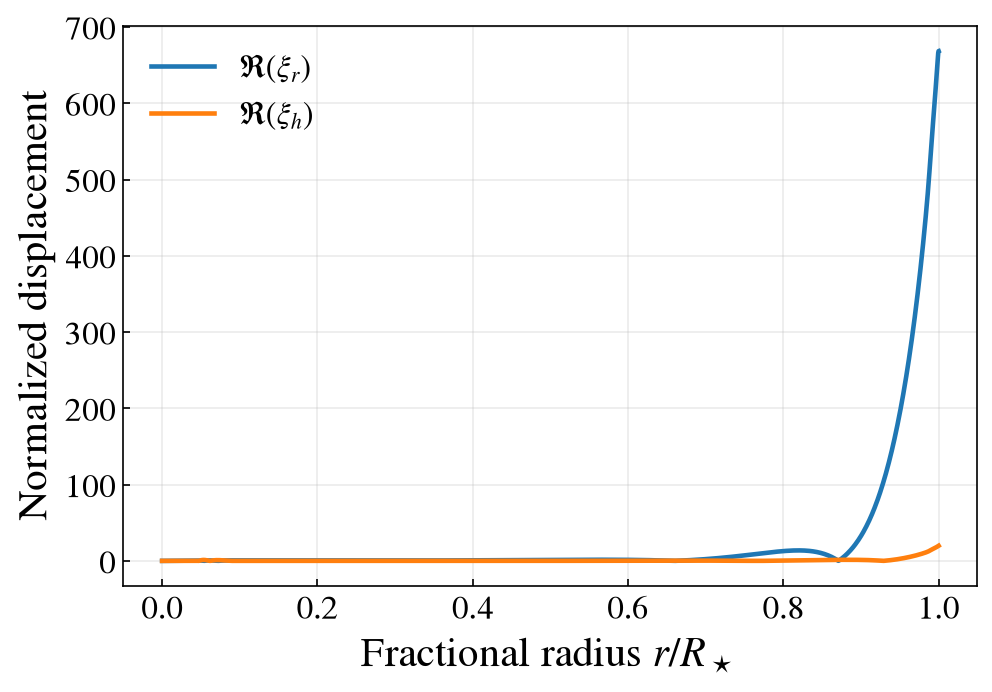

In [17]:
detail_files = sorted(OUTPUT_DIR.glob('detail.l*.n*.h5'))
if detail_files:
    detail = load_gyre_hdf5(detail_files[0])
    radius = np.asarray(detail['x'])
    xi_r = np.abs(np.asarray(detail['xi_r']))
    xi_h = np.abs(np.asarray(detail['xi_h']))

    fig, ax = plt.subplots(figsize=(6.5, 4.5), constrained_layout=True)
    ax.plot(radius, xi_r, label=r'$\Re(\xi_r)$')
    ax.plot(radius, xi_h, label=r'$\Re(\xi_h)$')
    ax.set_xlabel(r'Fractional radius $r/R_\star$')
    ax.set_ylabel(r'Normalized displacement')
    ax.tick_params(which='both', direction='in')
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    fig.savefig(OUTPUT_DIR / 'eigenfunctions.pdf', bbox_inches='tight')
    fig.savefig(OUTPUT_DIR / 'eigenfunctions.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No detail files yet; complete a real GYRE run first.')

## Interpretation

The mode table gives the radial-order classification and eigenfrequency. The detail files contain the radial dependence of the displacement eigenfunctions. Mode completeness depends on the chosen scan interval and resolution, so a production calculation should be checked by widening the interval and increasing `N_FREQ`.

n_pg: [-20 -19 -18 -17 -16 -15 -14 -13 -12 -11 -10  -9  -8  -7  -6  -5  -4  -3
  -2  -1   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15
  16  17  18  19  20]
Dimensionless omega: [ 1.10326911  1.17213563  1.21558167  1.30216169  1.36200567  1.45371733
  1.55753501  1.6264556   1.79179442  1.90697647  2.11300909  2.31421658
  2.55756119  2.89555067  3.15270595  3.55740417  3.95465401  4.23419113
  4.85702563  5.52085934  5.80197649  6.60421203  7.71014072  8.77663301
  8.95732832 10.02880599 11.18722507 12.37653007 13.58645515 14.8097792
 15.78185021 16.10458857 17.32248734 18.56253445 19.79134649 21.00576888
 22.21127831 23.42062544 24.64771323 25.89720115 27.1643395 ]
Frequency (cycles/day): [ 2.35210429  2.49892362  2.59154801  2.77613146  2.90371529  3.09923911
  3.32057225  3.46750685  3.8199994   4.06556071  4.50481002  4.93377246
  5.45256872  6.17314226  6.72138206  7.58417465  8.43108774  9.0270443
 10.3548905  11.77014459 12.36946969 14.07978826 16.43756262 18.

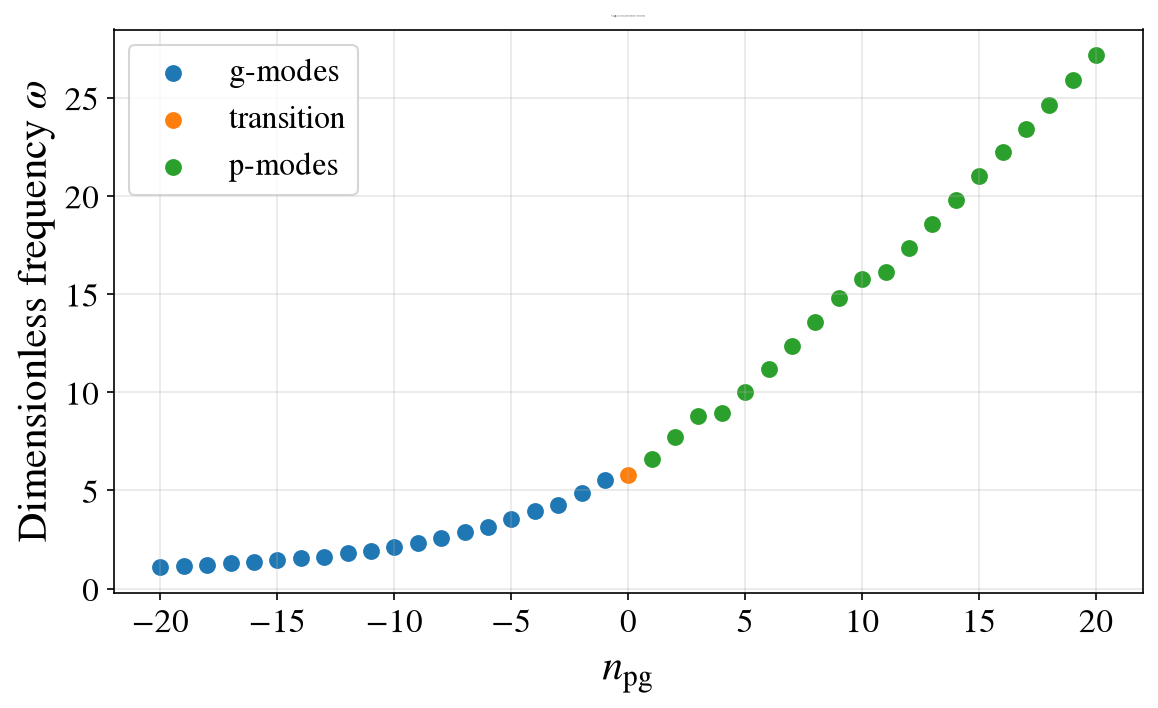

In [18]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SUMMARY = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/"
    "results/run_gyre/TAMS3Msun_Z0p0142/summary.h5"
)

with h5py.File(SUMMARY, "r") as f:
    n_pg = f["n_pg"][:]
    omega = f["omega"]["re"][:]
    freq = f["freq"]["re"][:]

print("n_pg:", n_pg)
print("Dimensionless omega:", omega)
print("Frequency (cycles/day):", freq)

# Identify modes
g_modes = n_pg < 0
p_modes = n_pg > 0
transition = n_pg == 0

fig, ax = plt.subplots(figsize=(8, 5))

# g-modes
ax.scatter(
    n_pg[g_modes],
    omega[g_modes],
    s=50,
    label="g-modes"
)

# Transition modes
ax.scatter(
    n_pg[transition],
    omega[transition],
    s=50,
    label="transition"
)

# p-modes
ax.scatter(
    n_pg[p_modes],
    omega[p_modes],
    s=50,
    label="p-modes"
)

ax.set_xlabel(r"$n_{\rm pg}$")
ax.set_ylabel(r"Dimensionless frequency $\omega$")
ax.set_title(r"1 M$_\odot$ MAMS Eigenfrequency Spectrum")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [111]:
with h5py.File(SUMMARY, "r") as f:
    for key in f.keys():
        print(key, f[key].shape)

    print("\nModes:")
    print("n_pg:", f["n_pg"][:])
    print("freq:", f["freq"]["re"][:])

E_norm (1,)
M_star (1,)
R_star (1,)
freq (1,)
l (1,)
n_g (1,)
n_p (1,)
n_pg (1,)
omega (1,)

Modes:
n_pg: [-70]
freq: [11.79435141]


In [108]:
with h5py.File(SUMMARY, "r") as f:
    def show_structure(name, obj):
        print(name, "->", type(obj).__name__)
        if isinstance(obj, h5py.Dataset):
            print("   shape:", obj.shape)
            print("   dtype:", obj.dtype)

    f.visititems(show_structure)

E_norm -> Dataset
   shape: (1,)
   dtype: float64
M_star -> Dataset
   shape: (1,)
   dtype: float64
R_star -> Dataset
   shape: (1,)
   dtype: float64
freq -> Dataset
   shape: (1,)
   dtype: [('re', '<f8'), ('im', '<f8')]
l -> Dataset
   shape: (1,)
   dtype: int32
n_g -> Dataset
   shape: (1,)
   dtype: int32
n_p -> Dataset
   shape: (1,)
   dtype: int32
n_pg -> Dataset
   shape: (1,)
   dtype: int32
omega -> Dataset
   shape: (1,)
   dtype: [('re', '<f8'), ('im', '<f8')]


In [78]:
import subprocess

result = subprocess.run(
    ["gyre", "--version"],
    capture_output=True,
    text=True
)

print("return code:", result.returncode)
print("stdout:", result.stdout)
print("stderr:", result.stderr)

return code: 2
stdout: gyre [9.1.1]
------------

OpenMP Threads   : 1
Input filename   : --version


stderr: At line 114 of file /Users/mchau/gyre-9.1.1/src/frontend/gyre/gyre.fypp
Fortran runtime error: Cannot open file '--version': No such file or directory



In [80]:
from pathlib import Path

run_dir = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/"
    "results/run_gyre/RGB1Msun_Z0p0142_logR1p6"
)

print("Files in run directory:")
for f in sorted(run_dir.iterdir()):
    print(f.name)

Files in run directory:
gyre.in
gyre.log
input_model.mesa
run_metadata.json


In [81]:
project_dir = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations"
)

h5_files = list(project_dir.rglob("*.h5"))

print("H5 files found:")
for f in h5_files:
    print(f)

H5 files found:
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR1p3/detail.l2.n-461.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR1p3/summary.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR1p3/detail.l2.n-68.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR1p0/detail.l2.n-285.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR1p0/detail.l2.n-420.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR1p0/summary.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR0p5/detail.l2.n-403.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR0p5/summary.h5
/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR0p5/detail.l2.n-185.h5
/Users/mch

In [90]:
from pathlib import Path
import os
import subprocess

GYRE = Path("/Users/mchau/gyre-9.1.1/bin/gyre")

RUN_DIR = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/"
    "results/run_gyre/RGB1Msun_Z0p0142_logR1p6"
)

print("GYRE:", GYRE)
print("Exists:", GYRE.exists())
print("Run directory:", RUN_DIR)
print("Exists:", RUN_DIR.exists())
print("\nFiles before run:")
for f in RUN_DIR.iterdir():
    print(" ", f.name)

GYRE: /Users/mchau/gyre-9.1.1/bin/gyre
Exists: True
Run directory: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/RGB1Msun_Z0p0142_logR1p6
Exists: True

Files before run:
  run_metadata.json
  input_model.mesa
  gyre.log
  gyre.in


In [91]:
os.environ["OMP_NUM_THREADS"] = "1"

result = subprocess.run(
    [str(GYRE), "gyre.in"],
    cwd=RUN_DIR,
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print("\nSTDOUT:")
print(result.stdout)

print("\nSTDERR:")
print(result.stderr)

print("\nFILES AFTER RUN:")
for f in RUN_DIR.iterdir():
    print(" ", f.name)

RETURN CODE: 0

STDOUT:
gyre [9.1.1]
------------

OpenMP Threads   : 1
Input filename   : gyre.in

Model Init
----------

Reading from MESA file
   File name input_model.mesa
   File version 1.01
   Read 1635 points
   No need to add central point

Mode Search
-----------

Mode parameters
   l : 2
   m : 0

Building frequency grid (REAL axis)
   added scan interval :  0.2515E+01 ->  0.1257E+03 (500 points, INVERSE)

Building spatial grid
   Scaffold grid from model
   Split 1273 subinterval(s) in iteration 1
   Split 2114 subinterval(s) in iteration 2
   Split 4201 subinterval(s) in iteration 3
   Split 8057 subinterval(s) in iteration 4
   Split 13142 subinterval(s) in iteration 5
   Split 21167 subinterval(s) in iteration 6
   Split 27136 subinterval(s) in iteration 7
   Split 20096 subinterval(s) in iteration 8
   Split 7168 subinterval(s) in iteration 9
   Split 1536 subinterval(s) in iteration 10
   Split 0 subinterval(s) in iteration 11
   Final grid has 6 segment(s) and 107525 